# Haqqi: understanding workers' labour problems in Arabic and English
**MAAI 902 (NLP & LLMs), Assessment 2 — University of Wollongong in Dubai**

## 0. Overview
A worker in the UAE describes a labour problem in Arabic or English. This notebook builds and evaluates a pipeline that:
1. **preprocesses** the message (language detection, Arabic normalisation, masking of personal details),
2. **classifies** the problem type (7 types),
3. **extracts facts** (amount, date, duration, employer),
4. **retrieves** the relevant articles of UAE Federal Decree-Law No. 33 of 2021 in **two hops** (similar Q&As, then law articles),
5. **generates** a plain-language answer that cites article numbers.

| Research question | Compared |
|---|---|
| RQ1 classification | TF-IDF + LR vs BGE-M3 + LR vs LLM prompting (Qwen3-8B, Jais 2 8B); macro-F1 per language |
| RQ2 fact extraction | rules vs LLM; precision / recall per fact type |
| RQ3 retrieval and answers | one hop vs two hops (recall@3 per language); answer quality: model alone / + Q&As / + Q&As and articles |

**How to run.** Upload `haqqi_drive_data.zip` to Google Drive and unzip it so that `MyDrive/haqqi/` contains `data/`, `results/` and `docs/`. Use a GPU runtime (Colab Pro: A100 or L4). Cells marked **⚡ GPU cell** need the GPU; every other cell runs on CPU. LLM outputs are cached on Drive, so a disconnect loses nothing: re-run the cell and it continues.

**Data note.** Training labels are *silver*: produced by an LLM (Claude Opus 5.5) following `docs/labelling_guide.md`, not verified by hand. The **test set** is a fixed 20% of the labelled questions (91: `data/labelled/rq1_dev_split.csv`), never used for training and **labelled blind by the author** (`data/labelled/test_labels.csv`, *human mode*). Without that file the notebook runs in *dev mode* (silver labels on the test questions), which only shows the code works. A separate **synthetic check** uses 17 made-up Arabic and English cases (section 8); it is reported apart from the test results.

## 1. Setup
Installs the libraries Colab does not have, mounts Google Drive and sets the data path. On Colab the data lives in `MyDrive/haqqi/`; when the notebook is run elsewhere (for testing) it uses the folder given by the `HAQQI_DATA` environment variable.

In [1]:
import sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # transformers must be recent: Qwen3 and Jais 2 need new model classes
    !pip -q install -U "transformers>=4.57" accelerate bitsandbytes sentence-transformers gradio

In [2]:
import json, math, os, re, time
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = Path("/content/drive/MyDrive/haqqi")
else:
    DATA = Path(os.environ.get("HAQQI_DATA", ".")).resolve()
os.chdir(DATA)                       # every path below is relative to this folder
for d in ("results/figures", "results/cache"):
    os.makedirs(d, exist_ok=True)

try:
    import torch
    HAS_GPU = torch.cuda.is_available()
except ImportError:
    HAS_GPU = False
print("data folder:", DATA, "| GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none (GPU cells will load caches)")

pd.set_option("display.max_colwidth", 80)
SEED = 42
PROBLEM_TYPES = ["unpaid_wages", "passport_withheld", "gratuity", "unfair_termination",
                 "recruitment_fees", "court_enforcement", "other"]
FACTS = ["amount", "date_mentioned", "duration", "employer"]
# chart colours: validated categorical palette (fixed order, never cycled)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
LANG_COLOR = {"ar": COLORS[0], "en": COLORS[1]}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.axisbelow": True, "figure.dpi": 110})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
data folder: /content/drive/MyDrive/haqqi | GPU: NVIDIA A100-SXM4-80GB


In [3]:
# Hugging Face login for the gated Jais 2 model: add a read token as the Colab secret HF_TOKEN
# (never paste a token into a cell)
if IN_COLAB:
    from google.colab import userdata
    from huggingface_hub import login
    try:
        login(token=userdata.get("HF_TOKEN"))
    except Exception as e:
        print("No HF_TOKEN secret: Jais 2 will be skipped.", e)

In [4]:
class Cache:
    """Answers saved on Drive, one JSON line each, so a disconnect loses nothing."""
    def __init__(self, name):
        self.path = Path(f"results/cache/{name}.jsonl")
        self.data = {}
        if self.path.exists():
            for line in self.path.read_text(encoding="utf-8").splitlines():
                row = json.loads(line)
                self.data[row["key"]] = row["value"]

    def get(self, key):
        return self.data.get(key)

    def put(self, key, value):
        self.data[key] = value
        with self.path.open("a", encoding="utf-8") as f:   # append + close = saved immediately
            f.write(json.dumps({"key": key, "value": value}, ensure_ascii=False) + "\n")

## 2. Data collection
Questions come from **Legal Advice Middle East** (legaladviceme.com/questions, *Employment*, UAE). Scraping was done once, locally, with Playwright: a 12-second pause between requests, an identifying user agent, no URLs disallowed by robots.txt (`lang=`), and raw HTML saved before any parsing. For Arabic only questions **written** in Arabic were kept: the Arabic listing also contains translated English questions, recognised by their English URL slug.

The scraper is shown below for reference; it is **not run** here (`RUN_SCRAPER = False`).

In [5]:
RUN_SCRAPER = False   # scraping was done once; never re-run it from Colab

QUESTION_RE = re.compile(r"^https?://(www\.)?legaladviceme\.com/questions/(\d+)/[^/?#]+")
ARABIC_LETTER = re.compile(r"[\u0600-\u06FF]")

def slug_lang(url):
    """'ar' if the URL slug is written in Arabic letters (question written in Arabic)."""
    from urllib.parse import unquote
    return "ar" if ARABIC_LETTER.search(unquote(url.rstrip("/").split("/")[-1])) else "en"

if RUN_SCRAPER:
    from playwright.sync_api import sync_playwright
    start = "https://legaladviceme.com/questions/ae?lawArea=5&language=41"   # 41 = English, 7 = Arabic
    with sync_playwright() as p:
        page = p.chromium.launch().new_page(user_agent="UOWD MAAI902 student research (contact: <email>)")
        for n in range(1, 71):
            page.goto(f"{start}&page={n}", wait_until="domcontentloaded")
            links = [h for h in page.eval_on_selector_all("a[href]", "els => els.map(e => e.href)")
                     if QUESTION_RE.match(h)]
            # ... saved to data/raw/links.csv; each question page saved as data/raw/html/<id>.html
            time.sleep(12)                                                      # polite delay

In [6]:
links = pd.read_csv("data/raw/links.csv")
print(f"{len(links)} links collected")
print(pd.crosstab(links["listing_lang"], links["slug_lang"]).rename_axis(index="listing", columns="slug"))
questions = pd.read_csv("data/clean/questions_clean.csv", encoding="utf-8-sig", dtype={"question_id": str},
                        keep_default_na=False)
print(f"\n{len(questions)} questions saved and parsed (title, full question text, date, lawyers' answers)")
questions[["question_id", "lang", "law_era", "date", "title", "n_answers"]].head()

3414 links collected


slug      ar    en
listing           
ar       253  2065
en         1  1095



999 questions saved and parsed (title, full question text, date, lawyers' answers)


,question_id,lang,law_era,date,title,n_answers
0,100281,en,current,"Aug 12, 2025",I have received a final judgment in my favor and the employer is offering to...,5
1,100305,en,current,"Aug 13, 2025",The employers are delaying my experience letter intentionally. What can I do?,6
2,100373,en,current,"Aug 14, 2025",My visa application was rejected twice after being in the UAE for five years...,4
3,100383,en,current,"Aug 14, 2025",Can I ask for an urgent decision to get a case judgment in order to release ...,1
4,100412,en,current,"Aug 16, 2025",An employee is resigning during probation. Can I reimburse the money I spent...,3


## 3. Preprocessing and data charts
The same preprocessing is applied to scraped questions and to new messages:
* **language**: share of Arabic letters → `ar`, `en` or `mixed`;
* **masking** of emails, URLs, Emirates ID numbers and phone numbers (names are not masked automatically);
* **Arabic normalisation**: diacritics and tatweel removed; alef forms, alef maksura and teh marbuta unified; Arabic-Indic digits to 0-9.

Questions asked before 2022 are kept but tagged `law_era = pre2022` (the old Federal Law No. 8 of 1980 applied).

In [7]:
AR_LETTER = re.compile(r"[\u0600-\u06FF\u0750-\u077F\u08A0-\u08FF]")
LATIN_LETTER = re.compile(r"[A-Za-z]")
DIACRITICS = re.compile(r"[\u0610-\u061A\u064B-\u065F\u0670\u06D6-\u06ED]")
AR_DIGITS = str.maketrans("٠١٢٣٤٥٦٧٨٩۰۱۲۳۴۵۶۷۸۹", "01234567890123456789")
EMAIL = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")
URL = re.compile(r"https?://\S+|www\.\S+")
EMIRATES_ID = re.compile(r"\b784[-\s]?\d{4}[-\s]?\d{7}[-\s]?\d\b")
PHONE = re.compile(r"(?:\+|00)?971[\s-]?\d{1,2}[\s-]?\d{3}[\s-]?\d{4}\b|\b0\d{1,2}[\s-]?\d{3}[\s-]?\d{4}\b")

def detect_language(text, mixed=0.2):
    ar, la = len(AR_LETTER.findall(text)), len(LATIN_LETTER.findall(text))
    if ar + la == 0:
        return "unknown"
    share = ar / (ar + la)
    return "ar" if share >= 1 - mixed else "en" if share <= mixed else "mixed"

def mask_pii(text):
    for pattern, tag in ((EMAIL, "[EMAIL]"), (URL, "[URL]"), (EMIRATES_ID, "[EID]"), (PHONE, "[PHONE]")):
        text = pattern.sub(tag, text)
    return text

def normalize_text(text):
    text = DIACRITICS.sub("", text).replace("\u0640", "")          # diacritics, tatweel
    text = re.sub("[إأآٱ]", "ا", text).replace("ى", "ي").replace("ة", "ه")
    return re.sub(r"\s+", " ", text.translate(AR_DIGITS).lower()).strip()

def preprocess(text):
    masked = mask_pii(text)
    return {"lang": detect_language(masked), "text_masked": masked, "text_norm": normalize_text(masked)}

for example in ["My employer has not paid me AED 5,000 for 3 months. Call 050 123 4567",
                "صاحب العمل لم يدفع راتبي منذ ٣ أشهر، رقم الهوية 784-1990-1234567-1"]:
    print(preprocess(example))

{'lang': 'en', 'text_masked': 'My employer has not paid me AED 5,000 for 3 months. Call [PHONE]', 'text_norm': 'my employer has not paid me aed 5,000 for 3 months. call [phone]'}
{'lang': 'ar', 'text_masked': 'صاحب العمل لم يدفع راتبي منذ ٣ أشهر، رقم الهوية [EID]', 'text_norm': 'صاحب العمل لم يدفع راتبي منذ 3 اشهر، رقم الهويه [eid]'}


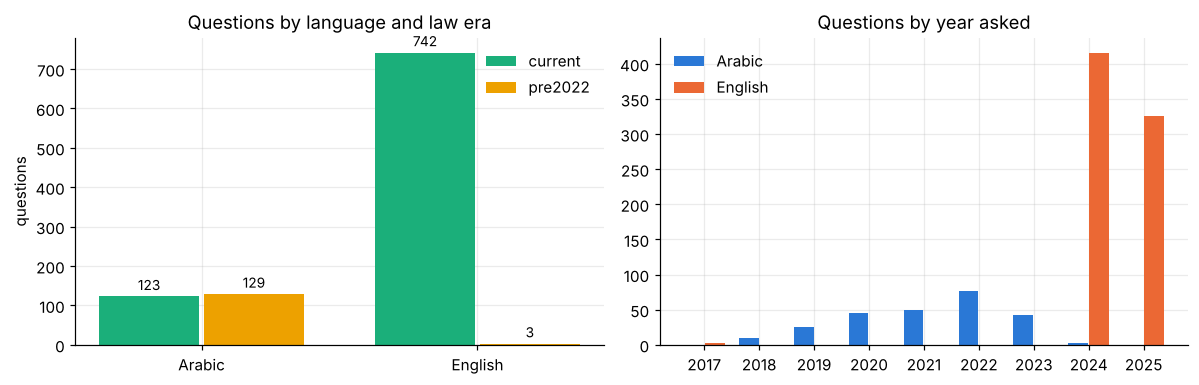

date  2017  2018  2019  2020  2021  2022  2023  2024  2025
lang                                                      
ar       0     9    25    46    49    77    43     3     0
en       3     0     0     0     0     0     0   416   326


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
counts = questions[questions["lang"].isin(["ar", "en"])].groupby(["lang", "law_era"]).size().unstack(fill_value=0)
x = np.arange(len(counts.index))
for k, era in enumerate(["current", "pre2022"]):
    # era colours differ from the language colours used in the right panel
    bars = axes[0].bar(x + (k - 0.5) * 0.38, counts[era], 0.36, label=era, color=COLORS[2 + k])
    axes[0].bar_label(bars, padding=2, fontsize=9)
axes[0].set_xticks(x, ["Arabic" if l == "ar" else "English" for l in counts.index])
axes[0].set_title("Questions by language and law era"); axes[0].set_ylabel("questions"); axes[0].legend(frameon=False)

years = pd.to_datetime(questions["date"], errors="coerce", format="mixed").dt.year
by_year = pd.crosstab(years, questions["lang"])[["ar", "en"]]
yx = np.arange(len(by_year.index))
for k, lang in enumerate(["ar", "en"]):
    axes[1].bar(yx + (k - 0.5) * 0.38, by_year[lang], 0.36, label={"ar": "Arabic", "en": "English"}[lang],
                color=LANG_COLOR[lang])
axes[1].set_xticks(yx, by_year.index.astype(int)); axes[1].set_title("Questions by year asked")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.savefig("results/figures/fig1_data.png", bbox_inches="tight"); plt.show()
print(by_year.T)

## 4. Labels
Each question has a `problem_type` (7 types, see the guide), who is asking (`worker`, `employer`, `unclear`) and facts copied exactly as written. `court_enforcement` was added at the labelling checkpoint: about 17% of questions ask how to enforce a judgment or follow court procedure in a case already filed.

* **Training (silver) labels**: 452 scraped questions labelled by an LLM following the guide; not independently verified (a blind check was started but stopped after 3 questions, too few to report).
* **Test set**: 91 questions held out from training (a fixed, stratified 20%), labelled again **by the author, blind**: in the labelling app's `--test` mode, which hides the LLM's suggestion and the lawyers' answers. These human labels (type and facts) are the test labels. Comparing them with the silver labels on the same questions measures how good the silver labels are.

In [9]:
print(open("docs/labelling_guide.md", encoding="utf-8").read()[:1500], "...")

# Labelling guide

## General
- Label from the question only, never from the lawyers' answers.
- One problem type per question. Explain any doubt in Notes.

## problem_type
- unpaid_wages: salary not paid, paid late, or paid only in part (including overtime and allowances).
- passport_withheld: employer keeps the passport, Emirates ID or other official documents.
- gratuity: end-of-service gratuity not paid, or a question about how much is owed.
- unfair_termination: dismissed without valid reason or without notice, or asking for compensation for dismissal.
- recruitment_fees: worker charged recruitment, visa or hiring costs by the employer or an agency.
- court_enforcement: the person already has a labour case, judgment or MOHRE decision and asks about the court process: enforcing or collecting a judgment, appeals, court fees, hearings, evidence, or amending or withdrawing a claim.
- other: anything else. Write a short topic in Notes (for example "visa ban", "annual leave", "notice pe

451 silver labels


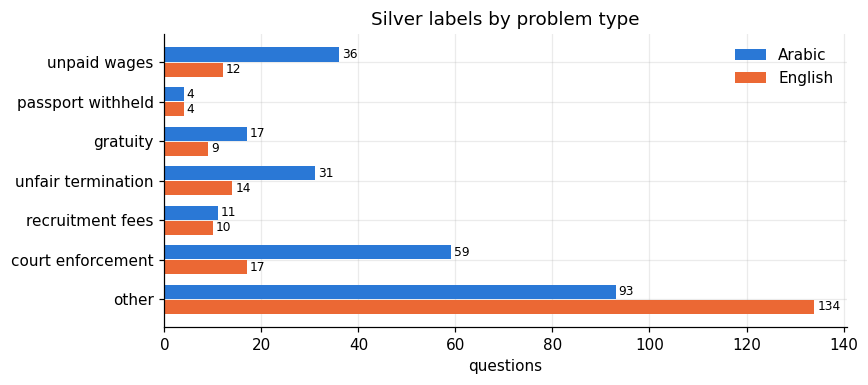

lang,ar,en
problem_type,,
unpaid_wages,36,12
passport_withheld,4,4
gratuity,17,9
unfair_termination,31,14
recruitment_fees,11,10
court_enforcement,59,17
other,93,134


In [10]:
silver = pd.read_csv("data/labelled/labelled.csv", encoding="utf-8-sig", dtype=str, keep_default_na=False)
silver = silver[(silver["source"] == "legaladviceme") & (silver["question_id"] != "44267")]  # 44267: text includes the answer
print(len(silver), "silver labels")

table = pd.crosstab(silver["problem_type"], silver["lang"]).reindex(PROBLEM_TYPES)
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(table.index))
for k, lang in enumerate(["ar", "en"]):
    bars = ax.barh(y + (k - 0.5) * 0.38, table[lang], 0.36, color=LANG_COLOR[lang],
                   label={"ar": "Arabic", "en": "English"}[lang])
    ax.bar_label(bars, padding=2, fontsize=8)
ax.set_yticks(y, [t.replace("_", " ") for t in table.index]); ax.invert_yaxis()
ax.set_title("Silver labels by problem type"); ax.set_xlabel("questions"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("results/figures/fig2_labels.png", bbox_inches="tight"); plt.show()
table

In [11]:
dev_ids = set(pd.read_csv("data/labelled/rq1_dev_split.csv", dtype=str)["question_id"])
train = silver[~silver["question_id"].isin(dev_ids)].reset_index(drop=True)
test = silver[silver["question_id"].isin(dev_ids)].reset_index(drop=True)

human_path = Path("data/labelled/test_labels.csv")       # the author's blind labels for the test questions
if human_path.exists():
    MODE = "human"
    human = pd.read_csv(human_path, encoding="utf-8-sig", dtype=str, keep_default_na=False)
    human = human[human["problem_type"].isin(PROBLEM_TYPES)].set_index("question_id")
    silver_test = test.set_index("question_id")["problem_type"]
    test = test[test["question_id"].isin(human.index)].reset_index(drop=True)
    for col in ["problem_type"] + FACTS:                   # human labels and facts replace the silver ones
        test[col] = test["question_id"].map(human[col])
    # how good are the silver labels? agreement with the author on the same questions
    from sklearn.metrics import cohen_kappa_score
    s_lab = test["question_id"].map(silver_test)
    print(f"silver vs human labels on {len(test)} test questions: agreement {(s_lab == test['problem_type']).mean():.2f}, "
          f"Cohen's kappa {cohen_kappa_score(s_lab, test['problem_type']):.2f}")
    display(pd.crosstab(s_lab.rename("silver"), test["problem_type"].rename("human")))
else:
    MODE = "dev"
print(f"MODE = {MODE}: {len(train)} train, {len(test)} test"
      + ("  (dev: silver labels on the test questions, NOT the result to report)" if MODE == "dev" else ""))
print(test["lang"].value_counts().to_dict())

silver vs human labels on 91 test questions: agreement 0.88, Cohen's kappa 0.82


human,court_enforcement,gratuity,other,passport_withheld,recruitment_fees,unfair_termination,unpaid_wages
silver,,,,,,,
court_enforcement,15,0,0,0,0,0,0
gratuity,0,1,3,0,0,0,1
other,1,0,45,0,0,0,0
passport_withheld,0,0,0,2,0,0,0
recruitment_fees,0,0,0,0,4,0,0
unfair_termination,1,0,1,0,0,7,0
unpaid_wages,2,0,0,0,0,2,6


MODE = human: 360 train, 91 test
{'ar': 48, 'en': 43}


## 5. RQ1: problem-type classifiers
Three approaches, all trained on the silver labels (the LLMs are zero-shot) and scored on the same test set with macro-F1 overall and per language:
1. **TF-IDF + logistic regression** (word 1-2-grams + character 2-5-grams, which handle Arabic prefixes and spelling variants);
2. **BGE-M3 embeddings + logistic regression** (multilingual sentence embeddings, frozen);
3. **LLM prompting**: the labelling guide as instructions, answer = one problem type. `Qwen/Qwen3-8B` (thinking switched off) and the Arabic-focused `inception42/Jais-2-8B-Chat`. Loaded in bfloat16, or 4-bit if the GPU has less than 20 GB.

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score
from sklearn.pipeline import FeatureUnion, Pipeline

RQ1 = {}   # model name -> list of predictions for `test`

def score_rq1(name, pred):
    """Macro-F1 and accuracy overall and per language; keeps the predictions in RQ1."""
    RQ1[name] = list(pred)
    rows = []
    for group in ["all", "ar", "en"]:
        m = np.ones(len(test), bool) if group == "all" else (test["lang"] == group).to_numpy()
        if m.sum() == 0:
            continue
        yt, yp = test["problem_type"][m], np.array(pred)[m]
        labels = sorted((set(yt) | set(yp)) & set(PROBLEM_TYPES))   # "no_answer" counts as wrong, not as a class
        rows.append({"model": name, "group": group, "n": int(m.sum()),
                     "macro_f1": round(f1_score(yt, yp, labels=labels, average="macro", zero_division=0), 3),
                     "accuracy": round(float((yt.to_numpy() == yp).mean()), 3)})
    return pd.DataFrame(rows)

tfidf = Pipeline([
    ("features", FeatureUnion([
        ("word", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True))])),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=5.0))])
tfidf.fit(train["text"].map(normalize_text), train["problem_type"])
rq1_tables = [score_rq1("TF-IDF + LR", tfidf.predict(test["text"].map(normalize_text)))]
rq1_tables[-1]

,model,group,n,macro_f1,accuracy
0,TF-IDF + LR,all,91,0.420,0.681
1,TF-IDF + LR,ar,48,0.402,0.688
2,TF-IDF + LR,en,43,0.256,0.674


In [13]:
# BGE-M3 embeddings were computed once for every scraped question (data/embeddings/).
# New questions (the Haqqi cases) are embedded here; this needs the model (GPU recommended).
emb_ids = pd.read_csv("data/embeddings/bge_m3_ids.csv", dtype=str)["question_id"].tolist()
emb = np.load("data/embeddings/bge_m3.npy")
EMB = dict(zip(emb_ids, emb))

_embedder = None
def embed(texts):
    """BGE-M3 sentence embeddings (unit length)."""
    global _embedder
    if _embedder is None:
        from sentence_transformers import SentenceTransformer
        _embedder = SentenceTransformer("BAAI/bge-m3", device="cuda" if HAS_GPU else "cpu")
        _embedder.max_seq_length = 512
    return _embedder.encode(list(texts), batch_size=16, normalize_embeddings=True, convert_to_numpy=True)

missing = test[~test["question_id"].isin(EMB)]
if len(missing):
    for qid, v in zip(missing["question_id"], embed(missing["text"])):
        EMB[qid] = v
print(f"{len(EMB)} embeddings ({len(missing)} new)")

bge_clf = LogisticRegression(max_iter=2000, class_weight="balanced", C=5.0)
bge_clf.fit(np.stack([EMB[q] for q in train["question_id"]]), train["problem_type"])
bge_pred = bge_clf.predict(np.stack([EMB[q] for q in test["question_id"]]))
rq1_tables.append(score_rq1("BGE-M3 + LR", bge_pred))
rq1_tables[-1]

999 embeddings (0 new)


,model,group,n,macro_f1,accuracy
0,BGE-M3 + LR,all,91,0.755,0.791
1,BGE-M3 + LR,ar,48,0.704,0.771
2,BGE-M3 + LR,en,43,0.793,0.814


In [14]:
LLM_MODELS = ["Qwen/Qwen3-8B", "inception42/Jais-2-8B-Chat"]
_llm = {"name": None, "model": None, "tok": None}

def get_llm(name):
    """Load one LLM at a time (bfloat16, or 4-bit if the GPU is small or bfloat16 fails)."""
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
    if _llm["name"] == name:
        return _llm
    if _llm["model"] is not None:                       # free the previous model first
        del _llm["model"]; torch.cuda.empty_cache()
    tok = AutoTokenizer.from_pretrained(name)
    big_gpu = torch.cuda.get_device_properties(0).total_memory / 1e9 >= 20
    four_bit = dict(quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                    bnb_4bit_compute_dtype=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16))
    try:
        kwargs = dict(dtype=torch.bfloat16) if big_gpu else four_bit
        model = AutoModelForCausalLM.from_pretrained(name, device_map="auto", **kwargs)
    except (torch.cuda.OutOfMemoryError, ValueError, RuntimeError) as e:
        print("bfloat16 failed, loading in 4-bit:", str(e)[:100]); torch.cuda.empty_cache()
        model = AutoModelForCausalLM.from_pretrained(name, device_map="auto", **four_bit)
    model.eval()
    _llm.update(name=name, model=model, tok=tok)
    print("loaded", name, "| 4-bit" if getattr(model, "is_loaded_in_4bit", False) else "| bfloat16")
    return _llm

def chat(name, prompt, max_new_tokens=32, sample=False):
    """One user turn -> the model's reply (Qwen3 thinking mode off)."""
    llm = get_llm(name)
    inputs = llm["tok"].apply_chat_template([{"role": "user", "content": prompt}], add_generation_prompt=True,
                                            return_tensors="pt", return_dict=True,
                                            enable_thinking=False).to(llm["model"].device)
    options = dict(do_sample=True, temperature=0.3) if sample else dict(do_sample=False)
    with torch.no_grad():
        out = llm["model"].generate(**inputs, max_new_tokens=max_new_tokens,
                                    pad_token_id=llm["tok"].eos_token_id, **options)
    return llm["tok"].decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def with_retries(fn, tries=3):
    """Run fn(attempt) until it returns something other than None (attempts 2-3 sample)."""
    for attempt in range(1, tries + 1):
        try:
            result = fn(attempt)
            if result is not None:
                return result
        except Exception as e:
            print("   retry after:", str(e)[:80])
    return None

In [15]:
GUIDE = open("docs/labelling_guide.md", encoding="utf-8").read()
CLASSIFY_PROMPT = ("You classify questions that people in the UAE posted about employment problems. "
                   "Follow the labelling guide below exactly. Answer with ONLY one of these values and nothing else: "
                   + ", ".join(PROBLEM_TYPES) + "\n\n<labelling_guide>\n" + GUIDE + "\n</labelling_guide>")

def parse_label(reply):
    """First allowed label in the reply ('unpaid wages' also accepted), else None."""
    text = reply.lower().replace("-", "_")
    hits = [(m.start(), lab) for lab in PROBLEM_TYPES for form in (lab, lab.replace("_", " "))
            for m in [re.search(r"\b" + re.escape(form) + r"\b", text)] if m]
    return min(hits)[1] if hits else None

def llm_classify(name, text):
    return with_retries(lambda attempt: parse_label(
        chat(name, CLASSIFY_PROMPT + "\n\n<question>\n" + text + "\n</question>", 20, sample=attempt > 1)))

print(parse_label("The answer is: unfair termination."), parse_label("لا أعرف"))

unfair_termination None


In [16]:
# ⚡ GPU cell: runs on the Colab GPU; elsewhere it loads cached results instead
for name in LLM_MODELS:
    cache = Cache(f"rq1_{name.split('/')[-1]}")
    todo = [q for q in test.itertuples() if cache.get(q.question_id) is None]
    if todo and HAS_GPU:
        print(f"{name}: {len(todo)} questions to classify")
        try:
            for i, q in enumerate(todo, 1):
                label = llm_classify(name, q.text)
                cache.put(q.question_id, label or "no_answer")   # unreadable after 3 tries: counted as wrong
                if i % 10 == 0:
                    print(f"  {i}/{len(todo)}")
        except Exception as e:     # e.g. Jais not accessible or too big: report and move on
            print(f"{name} skipped: {str(e)[:150]}")
    preds = [cache.get(q) for q in test["question_id"]]
    if all(preds):
        rq1_tables.append(score_rq1(name.split("/")[-1], preds))
        print(rq1_tables[-1], f"\n{preds.count('no_answer')} unreadable replies (counted as wrong)")
    else:
        print(f"{name}: {sum(p is not None for p in preds)}/{len(test)} cached"
              + ("" if HAS_GPU else " (no GPU here: run this cell on Colab)"))

      model group   n  macro_f1  accuracy
0  Qwen3-8B   all  91     0.662     0.725
1  Qwen3-8B    ar  48     0.573     0.708
2  Qwen3-8B    en  43     0.736     0.744 
1 unreadable replies (counted as wrong)
            model group   n  macro_f1  accuracy
0  Jais-2-8B-Chat   all  91     0.490     0.429
1  Jais-2-8B-Chat    ar  48     0.547     0.562
2  Jais-2-8B-Chat    en  43     0.398     0.279 
0 unreadable replies (counted as wrong)


In [17]:
rq1 = pd.concat(rq1_tables, ignore_index=True)
rq1.to_csv(f"results/nb_rq1_{MODE}.csv", index=False)
print(rq1.pivot(index="model", columns="group", values="macro_f1").reindex(columns=["all", "ar", "en"]))
for name, pred in RQ1.items():
    if name == "BGE-M3 + LR":
        print(f"\n{name} per class:\n", classification_report(test["problem_type"], pred, labels=PROBLEM_TYPES, zero_division=0))

group             all     ar     en
model                              
BGE-M3 + LR     0.755  0.704  0.793
Jais-2-8B-Chat  0.490  0.547  0.398
Qwen3-8B        0.662  0.573  0.736
TF-IDF + LR     0.420  0.402  0.256

BGE-M3 + LR per class:
                     precision    recall  f1-score   support

      unpaid_wages       0.58      1.00      0.74         7
 passport_withheld       1.00      1.00      1.00         2
          gratuity       0.20      1.00      0.33         1
unfair_termination       0.55      0.67      0.60         9
  recruitment_fees       0.80      1.00      0.89         4
 court_enforcement       0.94      0.89      0.92        19
             other       0.92      0.71      0.80        49

          accuracy                           0.79        91
         macro avg       0.71      0.90      0.75        91
      weighted avg       0.85      0.79      0.81        91



## 6. RQ2: fact extraction (rules vs LLM)
Facts to extract, **copied exactly as written** (empty if not stated): `amount`, `date_mentioned`, `duration` (how long the person worked for this employer) and `employer` (a company name).

* **Rules**: regular expressions for amounts (AED, dirham, درهم, ألف), English and Arabic dates, and durations in English and Arabic (digits and number words) that follow a work cue ("worked", "since", عملت, لمدة…). Company names cannot be found reliably with rules, so `employer` is always empty.
* **LLM**: Qwen3-8B with the guide's fact rules, answering in JSON.

Scoring: a prediction is correct if, ignoring spaces and commas, one value contains the other. Precision = correct / predicted, recall = correct / gold. The rules were written while looking at the silver labels, so dev-mode rule scores are optimistic; the Haqqi test set gives the unbiased comparison.

In [18]:
import re

EN_MONTHS = r"(?:jan(?:uary)?|feb(?:ruary)?|mar(?:ch)?|apr(?:il)?|may|june?|july?|aug(?:ust)?|sep(?:t(?:ember)?)?|oct(?:ober)?|nov(?:ember)?|dec(?:ember)?)"
AR_MONTHS = r"(?:يناير|فبراير|مارس|أبريل|ابريل|مايو|يونيو|يوليو|أغسطس|اغسطس|سبتمبر|أكتوبر|اكتوبر|نوفمبر|ديسمبر)"
NUM = r"\d[\d,\.:]*"                      # 5,000 / 5.000 / 50:000 (OCR-style) / 12000
EN_WORDNUM = r"(?:one|two|three|four|five|six|seven|eight|nine|ten|eleven|twelve|\d+(?:\.\d+)?)"
AR_DIGITS = str.maketrans("٠١٢٣٤٥٦٧٨٩", "0123456789")

AMOUNT = [
    rf"(?:AED|Dhs?\.?|dirhams?)\s?{NUM}\s?(?:k|thousand|million)?",
    rf"{NUM}\s?(?:k|thousand|million)?\s?(?:AED|dirhams?|Dhs)",
    rf"{NUM}\s?(?:ألف|الف|مليون)?\s?(?:درهم|دراهم)",
    rf"{NUM}\s?(?:ألف|الف|مليون)",
]
DATE = [
    rf"\b\d{{1,2}}(?:st|nd|rd|th)?\s(?:of\s)?{EN_MONTHS}\.?,?\s\d{{4}}",
    rf"\b{EN_MONTHS}\.?\s\d{{1,2}}(?:st|nd|rd|th)?,?\s\d{{4}}",
    rf"\b{EN_MONTHS}\.?,?\s\d{{4}}",
    r"\b\d{1,2}[/\-.]\d{1,2}[/\-.]\d{2,4}\b",
    rf"\d{{1,2}}\s?/?\s?{AR_MONTHS}\s?/?\s?\d{{4}}",
    rf"{AR_MONTHS}\s?\d{{4}}",
    r"(?:شهر\s)?\d{1,2}\s?/\s?\d{4}",
]
EN_DUR = rf"\b{EN_WORDNUM}(?:\.\d+)?\s(?:and a half\s)?(?:years?|months?|weeks?|days?)(?:\sand\s{EN_WORDNUM}\s(?:months?|days?))?"
AR_NUMWORD = r"(?:\d+|واحد|اثنا|اثني|ثلاث|ثلاثة|أربع|أربعة|اربع|خمس|خمسة|ست|ستة|سبع|سبعة|ثمان|ثماني|ثمانية|تسع|تسعة|عشر|عشرة)"
AR_DUR = r"(?:(?:\d+|واحد|اثنا|اثني|ثلاث|ثلاثة|أربع|أربعة|اربع|خمس|خمسة|ست|ستة|سبع|سبعة|ثمان|ثماني|ثمانية|تسع|تسعة|عشر|عشرة)\s?(?:سنوات|سنة|سنين|عاما|عامًا|عام|أعوام|أشهر|شهرا|شهرًا|شهر|شهور|أيام|يوما|يومًا|يوم)(?:\s?ونصف|\sو\s?\d+\s?(?:أشهر|شهور|شهر))?|(?:سنة|عام|شهر)\sونصف|سنتين|سنتان|شهرين|عامين|عامان|(?<=لمدة\s)شهر)"
# duration must be how long they worked for this employer: look for a work word just before it
WORK_CUE = r"(?:worked|working|work(?:ed)?\sfor|employed|been\swith|served|serving|service\sof|joined|for\sthe\spast|عملت|أعمل|اعمل|اشتغلت|عملي|خدمة|خدمتي|لمدة|منذ|قضيت|أمضيت|مدة|مدتها|بعد|أكملت|اكملت|completed|after|over|more\sthan|nearly|almost)"


def first_match(patterns, text):
    """Earliest match of any pattern, as written in the text."""
    hits = [m for p in patterns for m in [re.search(p, text, re.I)] if m]
    return min(hits, key=lambda m: m.start()).group(0).strip(" ,.") if hits else ""


def extract_rules(text: str) -> dict:
    t = text.translate(AR_DIGITS)
    duration = ""
    for m in re.finditer(rf"({EN_DUR}|{AR_DUR})", t, re.I):
        if re.search(WORK_CUE, t[max(0, m.start() - 45):m.start()], re.I):
            duration = m.group(0).strip()
            break
    return {"amount": first_match(AMOUNT, t), "date_mentioned": first_match(DATE, t),
            "duration": duration, "employer": ""}  # employer names: no reliable rule


def norm_fact(s: str) -> str:
    return re.sub(r"[\s,]", "", str(s).translate(AR_DIGITS).lower())


def fact_match(gold: str, pred: str) -> bool:
    """Lenient: either value contains the other after removing spaces and commas."""
    g, p = norm_fact(gold), norm_fact(pred)
    return bool(g and p and (g in p or p in g))


print(extract_rules("I worked for 3 years and the company owes me AED 12,000 since March 2024."))
print(extract_rules("عملت في الشركة لمدة سنتين ولم يدفعوا لي ٥٠٠٠ درهم منذ ١٢/٠٣/٢٠٢٤"))

{'amount': 'AED 12,000', 'date_mentioned': 'March 2024', 'duration': '3 years', 'employer': ''}
{'amount': '5000 درهم', 'date_mentioned': '12/03/2024', 'duration': 'سنتين', 'employer': ''}


In [19]:
# ⚡ GPU cell: runs on the Colab GPU; elsewhere it loads cached results instead
EXTRACT_PROMPT = ("Extract facts from a UAE worker's question, following the labelling guide below. "
                  "Copy each fact EXACTLY as written in the question, in the question's language; use \"\" "
                  "if it is not stated. Never translate, calculate or guess. Answer with only this JSON: "
                  '{"amount": "", "date_mentioned": "", "duration": "", "employer": ""}'
                  "\n\n<labelling_guide>\n" + GUIDE + "\n</labelling_guide>")

def parse_facts(reply):
    m = re.search(r"\{.*\}", reply, re.S)
    if not m:
        return None
    try:
        d = json.loads(m.group(0))
    except json.JSONDecodeError:
        return None
    return {f: str(d.get(f, "") or "") for f in FACTS}

def llm_extract(name, text):
    return with_retries(lambda attempt: parse_facts(
        chat(name, EXTRACT_PROMPT + "\n\n<question>\n" + text + "\n</question>", 120, sample=attempt > 1)))

EXTRACT_MODEL = "Qwen/Qwen3-8B"
cache = Cache(f"rq2_{EXTRACT_MODEL.split('/')[-1]}")
todo = [q for q in test.itertuples() if cache.get(q.question_id) is None]
if todo and HAS_GPU:
    print(f"{len(todo)} questions to extract")
    for i, q in enumerate(todo, 1):
        facts = llm_extract(EXTRACT_MODEL, q.text)
        if facts:
            cache.put(q.question_id, facts)
        if i % 10 == 0:
            print(f"  {i}/{len(todo)}")
llm_facts = {q: cache.get(q) for q in test["question_id"]}
print(f"LLM facts cached for {sum(v is not None for v in llm_facts.values())}/{len(test)} questions"
      + ("" if HAS_GPU else " (no GPU here)"))

LLM facts cached for 91/91 questions


In [20]:
def score_facts(method, predictions):
    rows = []
    for f in FACTS:
        gold = test[f].fillna("").tolist() if f in test else [""] * len(test)
        pred = [p.get(f, "") if p else "" for p in predictions]
        tp = sum(fact_match(g, p) for g, p in zip(gold, pred))
        n_pred, n_gold = sum(p != "" for p in pred), sum(g != "" for g in gold)
        rows.append({"method": method, "fact": f, "gold": n_gold, "predicted": n_pred, "correct": tp,
                     "precision": round(tp / n_pred, 3) if n_pred else np.nan,
                     "recall": round(tp / n_gold, 3) if n_gold else np.nan})
    return pd.DataFrame(rows)

rq2_tables = [score_facts("rules", [extract_rules(t) for t in test["text"]])]
if all(llm_facts.values()):
    rq2_tables.append(score_facts("LLM (Qwen3-8B)", [llm_facts[q] for q in test["question_id"]]))
rq2 = pd.concat(rq2_tables, ignore_index=True)
rq2.to_csv(f"results/nb_rq2_{MODE}.csv", index=False)
rq2

,method,fact,gold,predicted,correct,precision,recall
0,rules,amount,14,12,11,0.917,0.786
1,rules,date_mentioned,13,7,4,0.571,0.308
2,rules,duration,14,19,9,0.474,0.643
3,rules,employer,0,0,0,NaN,NaN
4,LLM (Qwen3-8B),amount,14,20,13,0.650,0.929
5,LLM (Qwen3-8B),date_mentioned,13,11,7,0.636,0.538
6,LLM (Qwen3-8B),duration,14,24,13,0.542,0.929
7,LLM (Qwen3-8B),employer,0,16,0,0.000,NaN


## 7. Law articles and keywords
**Federal Decree-Law No. 33 of 2021 on the Regulation of Labour Relations, with its amendments**: English from MoHRE, Arabic from u.ae. Both PDFs also contain the executive regulations (Cabinet Resolution No. 1 of 2022), which were skipped: the law ends at the President's signature after Article 74.

* English text was read directly (fixing the lost "h" of the "Th" ligature, e.g. "Te worker").
* The Arabic PDF's embedded text is unusable (broken letter shapes), so each page was read with **Tesseract OCR** (Arabic model). OCR makes small errors (e.g. ن/ت in a few titles). The Arabic PDF has the original fines in Article 60; the English one has the amended fines.

The splitter ran once locally (`src/law/split_articles.py`); its core is shown here and not re-run (`RUN_SPLITTER = False`). Then each article got a **keyword table** in English and Arabic, written the way workers phrase problems (`data/law/article_keywords.csv`, status *draft* until checked by the author).

In [21]:
RUN_SPLITTER = False   # needs the PDFs, PyMuPDF and Tesseract; output is data/law/articles.csv

if RUN_SPLITTER:
    import pymupdf, subprocess
    AR_HEAD = re.compile(r"^\s*ال?ماد[ةه]?\s*[\(\)]?\s*(\d{1,2})\s*[\(\)]?\s*(\*?)\s*$")   # "المادة (12)"
    doc = pymupdf.open("data/law/decree_law_33_2021_ar.pdf")
    for i, page in enumerate(doc):
        page.get_pixmap(dpi=300).save("page.png")                                          # page -> image
        text = subprocess.run(["tesseract", "page.png", "-", "-l", "ara", "--psm", "6"],
                              capture_output=True, text=True).stdout                       # image -> Arabic text
        # ... split at each "المادة (n)" heading (accepting only the next number), stop at the signature

articles = pd.read_csv("data/law/articles.csv", encoding="utf-8-sig", keep_default_na=False)
print(articles.groupby("lang").agg(articles=("article", "nunique"), median_chars=("text", lambda s: int(s.str.len().median()))))
articles[articles["article"].isin([29, 47])][["article", "lang", "title", "amended"]]

      articles  median_chars
lang                        
ar          74           481
en          74           772


,article,lang,title,amended
28,29,en,Annual Leave,False
46,47,en,Illegitimate Termination of the Worker’s Service,False
102,29,ar,الإجازة الستوية,False
120,47,ar,الانهاء غير المشروع لخدمة العامل,False


In [22]:
keywords = pd.read_csv("data/law/article_keywords.csv", encoding="utf-8-sig", keep_default_na=False)
AR_PREFIX = "[وفبلك]{0,2}"     # attached Arabic prefixes: و ف ب ل ك (e.g. "والإجازة")

TERMS = []   # (article, keyword as written, compiled pattern on normalised text)
for r in keywords.itertuples():
    for col, prefix in (("keywords_en", ""), ("keywords_ar", AR_PREFIX)):
        for term in getattr(r, col).split(";"):
            norm = normalize_text(term.strip())
            if norm:
                TERMS.append((int(r.article), term.strip(),
                              re.compile(r"(?<!\w)" + prefix + re.escape(norm) + r"(?!\w)")))

def matched_terms(text):
    """Indexes of the keywords found in text."""
    norm = normalize_text(text)
    return {i for i, (_, _, pattern) in enumerate(TERMS) if pattern.search(norm)}

print(f"{len(TERMS)} keywords for {keywords['keywords_en'].ne('').sum()} articles (status: {sorted(set(keywords['status']))})")
cover = silver["text"].map(lambda t: len({TERMS[i][0] for i in matched_terms(t)}) > 0)
print("questions matching at least one article from their own text:", cover.groupby(silver["lang"]).mean().round(2).to_dict())
keywords.loc[keywords["article"].isin([13, 47, 51]), ["article", "title_en", "keywords_en", "keywords_ar"]]

925 keywords for 74 articles (status: ['checked'])
questions matching at least one article from their own text: {'ar': 0.72, 'en': 0.66}


,article,title_en,keywords_en,keywords_ar
12,13,Employer’s Obligations,withheld passport; holding my passport; keeps my passport; passport not retu...,حجز الجواز; احتجاز جواز; جواز السفر محتجز; جوازي عند صاحب العمل; حجز الهوية;...
46,47,Illegitimate Termination of the Worker’s Service,unfair dismissal; unfair termination; arbitrary dismissal; wrongful terminat...,فصل تعسفي; الفصل التعسفي; إنهاء غير مشروع; فصل انتقامي; فصل بسبب شكوى للوزار...
50,51,End of Service Benefits for Full-Time Workers,gratuity; end of service benefits; end-of-service gratuity; eosb; gratuity c...,مكافأة نهاية الخدمة; حساب مكافأة نهاية الخدمة; مكافأة الخدمة; مستحقات نهاية ...


## 8. RQ3: two-hop retrieval, answers and evaluation
* **Hop 1** — for a question, the 10 most similar Q&As (BGE-M3 cosine) with the **same problem type**, from the 451 scraped questions with a lawyer answer. Never the question itself, nor a copy of it (cosine ≥ 0.98 or bodies ≥ 90% alike).
* **Hop 2** — each article is scored by its keywords found in the **question alone (one hop)** or in the **question plus its 10 Q&As (two hops)**; each keyword counts once per document, weighted by idf = log(N/df) so specific keywords count more. Top 3 articles.
* **Fair comparison**: the problem type for hop 1 is the **BGE-M3 classifier's prediction**, not the label, so two hops do not get the correct type for free.
* **Evaluation**: recall@3 against the author's problem-type → article map (`data/law/type_article_map.csv`), one hop vs two hops, per language.
* **Synthetic check** (end of this section) — 17 made-up Arabic and English cases, each listing its own correct articles: problem type and article retrieval, reported separately from the test results.
* **Answers** — an LLM answers from the question and facts (*model alone*), plus the Q&As (*+ Q&As*), plus the retrieved articles (*+ Q&As + articles*), citing article numbers. Compared with the real lawyer answer on scraped test questions.

In [23]:
import difflib

pool = questions[questions["n_answers"].astype(int) > 0][["question_id", "lang", "law_era", "title", "question", "answers"]]
pool = pool.merge(silver[["question_id", "problem_type"]], on="question_id").reset_index(drop=True)
pool_vecs = np.stack([EMB[q] for q in pool["question_id"]])
print(len(pool), "Q&As in the pool")

def hop1(qid, vec, body, problem_type, k=10):
    """Pool rows of the k most similar same-type Q&As (never the question or a copy of it)."""
    same = np.flatnonzero(pool["problem_type"].to_numpy() == problem_type)
    sims = pool_vecs[same] @ vec
    found = []
    for j in np.argsort(-sims):
        row = same[j]
        if pool.at[row, "question_id"] == qid or sims[j] >= 0.98:
            continue
        m = difflib.SequenceMatcher(None, body, pool.at[row, "question"])
        if m.quick_ratio() >= 0.9 and m.ratio() >= 0.9:          # same question posted again
            continue
        found.append(row)
        if len(found) == k:
            break
    return found

QA_TERMS = {r.question_id: matched_terms(" ".join([r.title, r.question, *json.loads(r.answers)]))
            for r in pool.itertuples()}
DF = Counter(i for doc in QA_TERMS.values() for i in doc)
IDF = {i: math.log(len(QA_TERMS) / DF[i]) if DF[i] else math.log(len(QA_TERMS)) for i in range(len(TERMS))}

def hop2(docs, top=3):
    """Top articles for a list of documents (each a set of keyword indexes): [(article, score, keywords)]."""
    score, found = defaultdict(float), defaultdict(set)
    for doc in docs:
        for i in doc:
            score[TERMS[i][0]] += IDF[i]
            found[TERMS[i][0]].add(TERMS[i][1])
    best = sorted(score, key=lambda a: (-score[a], a))[:top]
    return [(a, round(score[a], 2), sorted(found[a])) for a in best]

# retrieval for every test question, with the classifier's problem type
BODY = dict(zip(questions["question_id"], questions["question"]))   # question text without the title
retrieval = {}
for q, ptype in zip(test.itertuples(), bge_pred):
    body = BODY.get(q.question_id, q.text)
    neigh = hop1(q.question_id, EMB[q.question_id], body, ptype)
    q_doc = matched_terms(q.text)
    retrieval[q.question_id] = {"type": ptype, "neighbours": neigh,
                                "one_hop": hop2([q_doc]), "two_hop": hop2([q_doc] + [QA_TERMS[pool.at[r, "question_id"]] for r in neigh])}
q0 = test.iloc[0]
print(q0["title"] if "title" in test else q0["text"][:90])
for hops in ("one_hop", "two_hop"):
    print(f"  {hops}:", [(a, s) for a, s, _ in retrieval[q0["question_id"]][hops]])

451 Q&As in the pool
المستندات الواجب إرسالها للموظف خلال فترة الإشعار. السلام عليكم، الاستشارة القانونية ثم ال
  one_hop: [(43, 4.5)]
  two_hop: [(43, 39.94), (42, 20.71), (54, 13.63)]


In [24]:
map_path = Path("data/law/type_article_map.csv")
if map_path.exists():
    tmap = pd.read_csv(map_path, encoding="utf-8-sig", dtype=str, keep_default_na=False)
    tmap = tmap[tmap["article"].str.strip() != ""]
    GOLD = tmap.groupby("problem_type")["article"].apply(lambda s: {int(a) for a in s}).to_dict()
else:
    GOLD = {}
    print("No data/law/type_article_map.csv yet: fill in data/law/type_article_map_template.csv to get recall@3.")

rows = []
for q in test.itertuples():
    gold = GOLD.get(q.problem_type)       # judged by the TRUE problem type
    if not gold:
        continue                          # e.g. 'other' has no fixed articles
    for hops in ("one_hop", "two_hop"):
        top = {a for a, _, _ in retrieval[q.question_id][hops]}
        rows.append({"hops": hops, "lang": q.lang, "problem_type": q.problem_type,
                     "recall_at_3": len(gold & top) / min(len(gold), 3), "hit_at_3": int(bool(gold & top))})
rq3_recall = pd.DataFrame(rows)
if len(rq3_recall):
    summary = pd.concat([rq3_recall.groupby(["hops", "lang"])[["recall_at_3", "hit_at_3"]].mean(),
                         rq3_recall.groupby("hops")[["recall_at_3", "hit_at_3"]].mean()
                         .assign(lang="all").set_index("lang", append=True)]).round(3)
    summary.to_csv(f"results/nb_rq3_recall_{MODE}.csv")
    display(summary)

recall_at_3  hit_at_3
hops    lang                       
one_hop ar          0.167     0.481
        en          0.133     0.267
two_hop ar          0.469     0.963
        en          0.489     0.933
one_hop all         0.155     0.405
two_hop all         0.476     0.952

In [25]:
# ⚡ GPU cell: runs on the Colab GPU; elsewhere it loads cached results instead
# questions for the answer comparison: scraped test questions asked under the current law, with a lawyer answer
answer_set = (test.merge(pool[["question_id", "answers"]], on="question_id")
                  .merge(questions[["question_id", "law_era", "title"]], on="question_id", suffixes=("", "_q")))
answer_set = answer_set[answer_set["law_era_q"] == "current"] if "law_era_q" in answer_set else answer_set[answer_set["law_era"] == "current"]
ANSWER_N = 15                                                            # per language
answer_set = pd.concat([g.sample(min(ANSWER_N, len(g)), random_state=SEED)
                        for _, g in answer_set.groupby("lang")], ignore_index=True)
print(len(answer_set), "questions for the answer comparison:", answer_set["lang"].value_counts().to_dict())

ART_TEXT = {(r.article, r.lang): (r.title, r.text) for r in articles.itertuples()}

def answer_prompt(q, condition):
    """condition: 'alone', 'qas' or 'qas_articles'."""
    lang = "Arabic" if q.lang == "ar" else "English"
    parts = [f"You help workers in the UAE understand their rights under Federal Decree-Law No. 33 of 2021. "
             f"Answer the worker's question in plain {lang} in at most 180 words. Cite article numbers of the "
             f"Decree-Law (e.g. 'Article 51') only when you are confident they apply. Do not invent facts.",
             f"<question>\n{q.text}\n</question>",
             f"<facts>\n{json.dumps(extract_rules(q.text), ensure_ascii=False)}\n</facts>"]
    r = retrieval[q.question_id]
    if condition in ("qas", "qas_articles"):
        qas = [f"Q: {pool.at[row, 'title']}\nA: {json.loads(pool.at[row, 'answers'])[0][:600]}" for row in r["neighbours"]]
        parts.append("<similar_questions_answered_by_lawyers>\n" + "\n\n".join(qas) + "\n</similar_questions_answered_by_lawyers>")
    if condition == "qas_articles":
        arts = []
        for a, _, _ in r["two_hop"]:
            title, text = ART_TEXT.get((a, q.lang), ART_TEXT[(a, "en")])
            arts.append(f"Article {a} ({title}):\n{text[:1500]}")
        parts.append("<law_articles>\n" + "\n\n".join(arts) + "\n</law_articles>")
    return "\n\n".join(parts)

CONDITIONS = ["alone", "qas", "qas_articles"]
ANSWER_MODEL = "Qwen/Qwen3-8B"
answers_cache = Cache(f"rq3_answers_{ANSWER_MODEL.split('/')[-1]}")
todo = [(q, c) for q in answer_set.itertuples() for c in CONDITIONS if answers_cache.get(f"{c}|{q.question_id}") is None]
if todo and HAS_GPU:
    print(len(todo), "answers to generate")
    for i, (q, c) in enumerate(todo, 1):
        reply = with_retries(lambda attempt: chat(ANSWER_MODEL, answer_prompt(q, c), 400, sample=attempt > 1) or None)
        if reply:
            answers_cache.put(f"{c}|{q.question_id}", reply)
        if i % 10 == 0:
            print(f"  {i}/{len(todo)}")
done = sum(answers_cache.get(f"{c}|{q}") is not None for q in answer_set["question_id"] for c in CONDITIONS)
print(f"{done}/{len(answer_set) * len(CONDITIONS)} answers cached" + ("" if HAS_GPU else " (no GPU here)"))

30 questions for the answer comparison: {'ar': 15, 'en': 15}
90 answers to generate


Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

loaded Qwen/Qwen3-8B | bfloat16
  10/90
  20/90
  30/90
  40/90
  50/90
  60/90
  70/90
  80/90
  90/90
90/90 answers cached


In [26]:
# ⚡ GPU cell: runs on the Colab GPU; elsewhere it loads cached results instead
# answer quality: similarity to the real lawyer answer (BGE-M3 cosine), article citations, language
CITE = re.compile(r"(?:article|art\.?|المادة|مادة)\s*\(?\s*(\d{1,2})\s*\)?", re.I)
rows = []
if done == len(answer_set) * len(CONDITIONS):
    lawyer = embed([json.loads(a)[0] for a in answer_set["answers"]])
    for c in CONDITIONS:
        gen = [answers_cache.get(f"{c}|{q}") for q in answer_set["question_id"]]
        sims = (embed(gen) * lawyer).sum(axis=1)
        for q, g, s in zip(answer_set.itertuples(), gen, sims):
            cited = {int(n) for n in CITE.findall(g.translate(AR_DIGITS))}
            rows.append({"condition": c, "lang": q.lang, "similarity_to_lawyer": float(s),
                         "cites_any_article": int(bool(cited)),
                         "cites_mapped_article": int(bool(cited & GOLD[q.problem_type])) if q.problem_type in GOLD else np.nan,
                         "same_language": int(detect_language(g) == q.lang)})
    rq3_answers = pd.DataFrame(rows)
    rq3_answers_summary = rq3_answers.groupby(["condition", "lang"]).mean(numeric_only=True).round(3)
    rq3_answers_summary.to_csv(f"results/nb_rq3_answers_{MODE}.csv")
    display(rq3_answers_summary)
else:
    rq3_answers = pd.DataFrame()
    print("Answers not generated yet (GPU cell above).")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

similarity_to_lawyer  cites_any_article  \
condition    lang                                            
alone        ar                   0.649              0.733   
             en                   0.765              0.800   
qas          ar                   0.678              0.600   
             en                   0.782              0.667   
qas_articles ar                   0.657              0.733   
             en                   0.764              0.933   

                   cites_mapped_article  same_language  
condition    lang                                       
alone        ar                   0.000            1.0  
             en                   0.000            1.0  
qas          ar                   0.000            1.0  
             en                   0.000            1.0  
qas_articles ar                   0.429            1.0  
             en                   0.833            1.0

### Synthetic check: 17 made-up cases
The Haqqi app's evaluation set (`data/synthetic/cases.jsonl`) has 50 made-up cases. The 17 in Arabic or English that the law covers are used here (`src/label/convert_synthetic_cases.py`); the other 33 are in other languages, out of scope or lack information. Each case lists the articles its answer must rest on (**key articles**), which gives a per-case check of retrieval instead of the per-type map. The problem type was mapped by hand to the 7 types (main or first-mentioned problem). Some cases contain a prompt-injection sentence; they are kept. **These cases are synthetic, so this is a sanity check, not a test result.**

In [27]:
syn = pd.read_csv("data/synthetic/synthetic_cases.csv", encoding="utf-8-sig", dtype=str, keep_default_na=False)
syn["question_id"] = "syn_" + syn["id"]
syn["text"] = syn["text"].map(lambda t: preprocess(t)["text_masked"])
missing = syn[~syn["question_id"].isin(EMB)]
if len(missing):
    for qid, v in zip(missing["question_id"], embed(missing["text"])):
        EMB[qid] = v
syn_vecs = np.stack([EMB[q] for q in syn["question_id"]])
syn_pred = {"TF-IDF + LR": tfidf.predict(syn["text"].map(normalize_text)), "BGE-M3 + LR": bge_clf.predict(syn_vecs)}
print(len(syn), "synthetic cases:", syn["lang"].value_counts().to_dict())

17 synthetic cases: {'en': 13, 'ar': 4}


In [28]:
# ⚡ GPU cell: runs on the Colab GPU; elsewhere it loads cached results instead
for name in LLM_MODELS:      # same LLM caches as RQ1; the synthetic cases have their own keys
    cache = Cache(f"rq1_{name.split('/')[-1]}")
    todo = [q for q in syn.itertuples() if cache.get(q.question_id) is None]
    if todo and HAS_GPU:
        try:
            for q in todo:
                label = llm_classify(name, q.text)
                cache.put(q.question_id, label or "no_answer")   # unreadable after 3 tries: counted as wrong
        except Exception as e:
            print(f"{name} skipped: {str(e)[:150]}")
    preds = [cache.get(q) for q in syn["question_id"]]
    if all(preds):
        syn_pred[name.split("/")[-1]] = np.array(preds)
    else:
        print(f"{name}: {sum(p is not None for p in preds)}/{len(syn)} cached" + ("" if HAS_GPU else " (no GPU here)"))

Loading weights:   0%|          | 0/516 [00:00<?, ?it/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


loaded inception42/Jais-2-8B-Chat | bfloat16


In [29]:
# problem type: accuracy per classifier
syn_rows = [{"check": "problem type accuracy", "method": m, "lang": g, "n": int(mask.sum()),
             "value": round(float((syn["problem_type"][mask].to_numpy() == p[mask]).mean()), 3)}
            for m, p in syn_pred.items()
            for g, mask in [("all", np.ones(len(syn), bool)), ("ar", (syn["lang"] == "ar").to_numpy()),
                            ("en", (syn["lang"] == "en").to_numpy())]]

# articles: one hop vs two hops, problem type from the BGE-M3 classifier (as in RQ3)
ret_rows = []
for q, vec, ptype in zip(syn.itertuples(), syn_vecs, syn_pred["BGE-M3 + LR"]):
    gold = {int(a) for a in q.key_articles.split(";") if a}
    if not gold:
        continue                                            # TC-12: not covered by the labour law
    neigh = hop1(q.question_id, vec, q.text, ptype)
    q_doc = matched_terms(q.text)
    for hops, docs in (("one_hop", [q_doc]), ("two_hop", [q_doc] + [QA_TERMS[pool.at[r, "question_id"]] for r in neigh])):
        top = {a for a, _, _ in hop2(docs)}
        ret_rows.append({"hops": hops, "lang": q.lang, "id": q.id, "top3": sorted(top), "key": sorted(gold),
                         "recall_at_3": len(gold & top) / min(len(gold), 3), "hit_at_3": int(bool(gold & top))})
syn_ret = pd.DataFrame(ret_rows)
for metric in ("recall_at_3", "hit_at_3"):
    for hops, g in syn_ret.groupby("hops"):
        for lang, gl in [("all", g)] + list(g.groupby("lang")):
            syn_rows.append({"check": f"key articles {metric}", "method": hops, "lang": lang,
                             "n": len(gl), "value": round(gl[metric].mean(), 3)})
syn_check = pd.DataFrame(syn_rows)
syn_check.to_csv("results/nb_synthetic_check.csv", index=False)
display(syn_check.pivot_table(index=["check", "method"], columns="lang", values="value"))
syn_ret[syn_ret["hops"] == "two_hop"][["id", "lang", "key", "top3", "hit_at_3"]]

lang                                       all     ar     en
check                    method                             
key articles hit_at_3    one_hop         0.625  0.500  0.667
                         two_hop         1.000  1.000  1.000
key articles recall_at_3 one_hop         0.458  0.333  0.500
                         two_hop         0.823  0.917  0.792
problem type accuracy    BGE-M3 + LR     0.882  0.750  0.923
                         Jais-2-8B-Chat  0.824  1.000  0.769
                         Qwen3-8B        0.941  0.750  1.000
                         TF-IDF + LR     0.412  0.750  0.308

,id,lang,key,top3,hit_at_3
1,TC-03,en,[51],"[29, 42, 51]",1
3,TC-10,en,[22],"[8, 22, 54]",1
5,TC-11,en,[22],"[8, 13, 22]",1
7,TC-18,en,[22],"[8, 13, 22]",1
9,TC-19,en,"[42, 43]","[8, 29, 42]",1
11,TC-20,en,"[42, 43, 51]","[29, 43, 51]",1
13,TC-21,en,"[22, 51]","[13, 22, 42]",1
15,TC-22,en,[29],"[29, 30, 54]",1
17,TC-23,ar,[22],"[8, 22, 47]",1
19,N-07,ar,"[22, 42, 43, 51]","[8, 22, 42]",1


## 9. Results: tables, charts and live demo
All tables are also saved in `results/` (`nb_*_{mode}.csv`) and the charts in `results/figures/`.

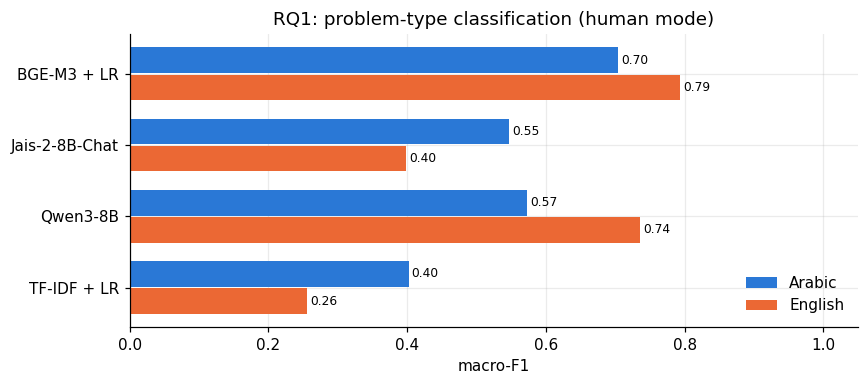

group,all,ar,en
model,,,
BGE-M3 + LR,0.755,0.704,0.793
Jais-2-8B-Chat,0.490,0.547,0.398
Qwen3-8B,0.662,0.573,0.736
TF-IDF + LR,0.420,0.402,0.256


In [30]:
# RQ1: macro-F1 per model and language
pivot = rq1.pivot(index="model", columns="group", values="macro_f1").reindex(columns=["all", "ar", "en"])
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(pivot.index))
for k, group in enumerate(["ar", "en"]):
    bars = ax.barh(y + (k - 0.5) * 0.38, pivot[group], 0.36, color=LANG_COLOR[group],
                   label={"ar": "Arabic", "en": "English"}[group])
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)
ax.set_yticks(y, pivot.index); ax.invert_yaxis(); ax.set_xlim(0, 1.05)
ax.set_xlabel("macro-F1"); ax.legend(frameon=False, loc="lower right")
ax.set_title(f"RQ1: problem-type classification ({MODE} mode)")
plt.tight_layout(); plt.savefig(f"results/figures/fig3_rq1_{MODE}.png", bbox_inches="tight"); plt.show()
pivot

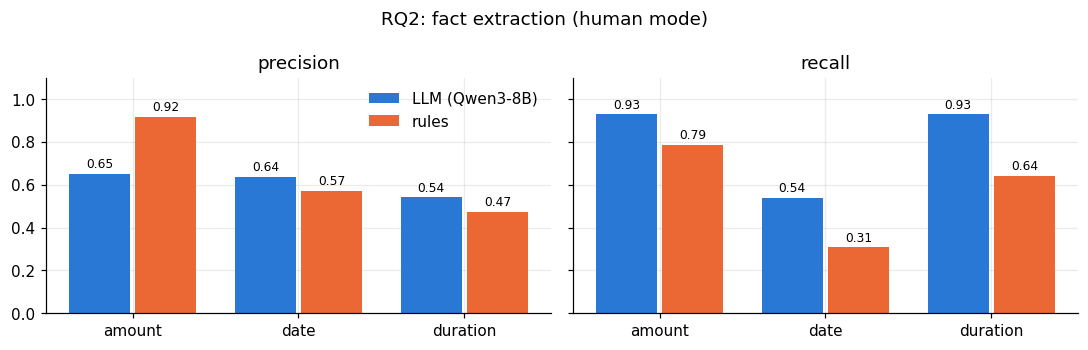

In [31]:
# RQ2: precision and recall per fact
show = rq2[rq2["fact"] != "employer"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, metric in zip(axes, ["precision", "recall"]):
    p = show.pivot(index="fact", columns="method", values=metric)
    x = np.arange(len(p.index))
    w = 0.8 / len(p.columns)
    for k, method in enumerate(p.columns):
        bars = ax.bar(x + (k - (len(p.columns) - 1) / 2) * w, p[method], w * 0.92, color=COLORS[k], label=method)
        ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)
    ax.set_xticks(x, [f.replace("_mentioned", "") for f in p.index]); ax.set_ylim(0, 1.1); ax.set_title(metric)
axes[0].legend(frameon=False)
fig.suptitle(f"RQ2: fact extraction ({MODE} mode)")
plt.tight_layout(); plt.savefig(f"results/figures/fig4_rq2_{MODE}.png", bbox_inches="tight"); plt.show()

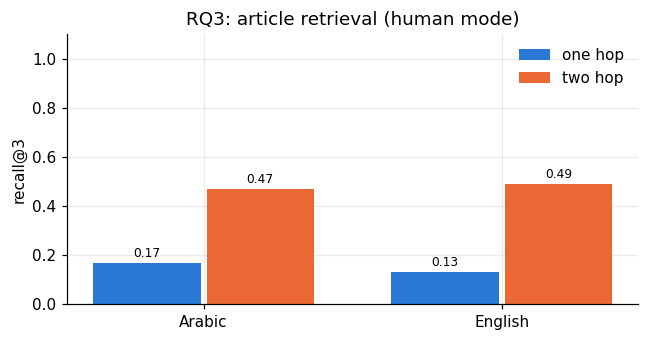

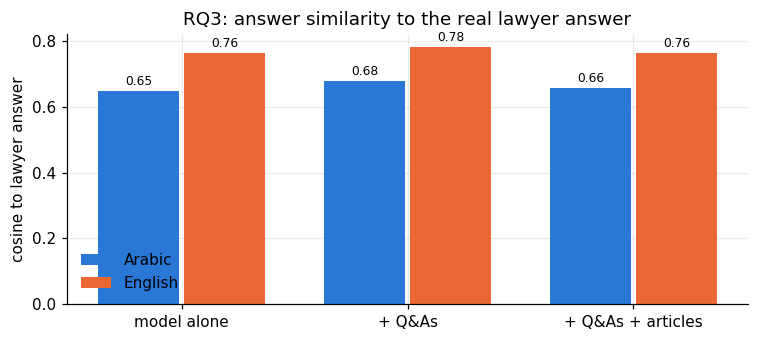

In [32]:
# RQ3: recall@3 one hop vs two hops, and answer quality
if len(rq3_recall):
    r = rq3_recall.groupby(["lang", "hops"])["recall_at_3"].mean().unstack()
    fig, ax = plt.subplots(figsize=(6, 3.2))
    x = np.arange(len(r.index))
    for k, hops in enumerate(["one_hop", "two_hop"]):
        bars = ax.bar(x + (k - 0.5) * 0.38, r[hops], 0.36, color=COLORS[k], label=hops.replace("_", " "))
        ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)
    ax.set_xticks(x, ["Arabic" if l == "ar" else "English" for l in r.index]); ax.set_ylim(0, 1.1)
    ax.set_ylabel("recall@3"); ax.legend(frameon=False); ax.set_title(f"RQ3: article retrieval ({MODE} mode)")
    plt.tight_layout(); plt.savefig(f"results/figures/fig5_rq3_recall_{MODE}.png", bbox_inches="tight"); plt.show()
else:
    print("RQ3 recall needs data/law/type_article_map.csv.")
if len(rq3_answers):
    a = rq3_answers.groupby(["condition", "lang"])["similarity_to_lawyer"].mean().unstack().reindex(CONDITIONS)
    fig, ax = plt.subplots(figsize=(7, 3.2))
    x = np.arange(len(a.index))
    for k, lang in enumerate(["ar", "en"]):
        bars = ax.bar(x + (k - 0.5) * 0.38, a[lang], 0.36, color=LANG_COLOR[lang], label={"ar": "Arabic", "en": "English"}[lang])
        ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)
    ax.set_xticks(x, ["model alone", "+ Q&As", "+ Q&As + articles"]); ax.set_ylabel("cosine to lawyer answer")
    ax.legend(frameon=False); ax.set_title("RQ3: answer similarity to the real lawyer answer")
    plt.tight_layout(); plt.savefig(f"results/figures/fig6_rq3_answers_{MODE}.png", bbox_inches="tight"); plt.show()

### Live demo
Type a worker's message in Arabic or English. The demo runs the whole pipeline: preprocessing → BGE-M3 classifier → rule-based facts → hop 1 (similar Q&As) → hop 2 (articles) → Qwen3-8B answer citing articles. **Not legal advice.**

In [33]:
# ⚡ GPU cell: runs on the Colab GPU; elsewhere it loads cached results instead
def haqqi_pipeline(message):
    p = preprocess(message)
    vec = embed([p["text_masked"]])[0]
    ptype = bge_clf.predict(vec[None, :])[0]
    facts = extract_rules(p["text_masked"])
    neigh = hop1("", vec, p["text_masked"], ptype)
    q_doc = matched_terms(p["text_masked"])
    arts = hop2([q_doc] + [QA_TERMS[pool.at[r, "question_id"]] for r in neigh])
    retrieval["demo"] = {"type": ptype, "neighbours": neigh, "one_hop": hop2([q_doc]), "two_hop": arts}
    q = pd.Series({"question_id": "demo", "text": p["text_masked"], "lang": p["lang"] if p["lang"] in ("ar", "en") else "en"})
    answer = chat(ANSWER_MODEL, answer_prompt(q, "qas_articles"), 400)
    art_list = "\n".join(f"Article {a}: {ART_TEXT.get((a, 'en'), ('', ''))[0]} (score {s})" for a, s, _ in arts)
    similar = "\n".join(f"- {pool.at[r, 'title']}" for r in neigh[:5])
    return ptype.replace("_", " "), json.dumps(facts, ensure_ascii=False, indent=1), art_list, similar, answer

if HAS_GPU:
    import gradio as gr
    gr.Interface(fn=haqqi_pipeline,
                 inputs=gr.Textbox(lines=5, label="Your message (Arabic or English)"),
                 outputs=[gr.Textbox(label="Problem type"), gr.Textbox(label="Facts"), gr.Textbox(label="Articles (two hops)"),
                          gr.Textbox(label="Similar questions"), gr.Textbox(label="Answer (Qwen3-8B)", lines=10)],
                 title="Haqqi: understand your labour problem",
                 examples=["My company has not paid my salary for 3 months and is keeping my passport.",
                           "تم فصلي من العمل بعد خمس سنوات بدون سبب، ما هي حقوقي؟"]).launch(share=True)
else:
    print("The demo needs the GPU (Colab).")

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6951aefaf78691097b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 10. Ethics and limitations
**Data and consent.** Questions are public posts on Legal Advice Middle East, collected politely (12-second delay, identifying user agent, robots.txt respected, no logged-in pages). Emails, phone numbers, Emirates IDs and URLs are masked; personal names are not masked automatically and were flagged (`PII`) during labelling. The synthetic cases describe no real people.

**Labels.** Training labels are LLM-made (silver) and were not verified one by one; classifiers trained on them partly learn to imitate the labelling LLM. The 91 test questions were labelled blind by the author, and their agreement with the silver labels (section 4) estimates the silver labels' quality. Only human-mode numbers are results; dev-mode numbers are not. The 17 synthetic cases are made up and their problem types were mapped by hand, so the synthetic check is a sanity check only.

**Class imbalance and coverage.** `other` is about half the data and `passport_withheld` has only 8 examples, so its per-class scores are unstable. Arabic data is small (123 current-law questions) because few Arabic questions were posted after 2023; half of the Arabic questions predate the current law.

**Law text.** The Arabic articles come from OCR and contain small errors; the Arabic PDF's Article 60 shows the original fines. Questions asked before 2022 refer to the old law, and their lawyers' answers may cite old article numbers.

**Retrieval and answers.** The keyword table is a draft until checked by the author, and recall@3 depends on the author's article map. Hop 1 uses the classifier's predicted type so the two-hop comparison is fair. Answer quality is measured automatically (similarity to one lawyer answer, citations), which does not prove legal correctness. **The system is a research prototype and gives no legal advice**: answers can be wrong or outdated, and workers should contact MoHRE or a lawyer.

**Use of generative AI.** Generative AI (Claude) was used to help write the code and to produce the silver training labels, as the subject outline requires to be acknowledged.